<a href="https://colab.research.google.com/github/JoyMwaniki/30-Days-Of-Python/blob/master/Kenya_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

6121 cells of 10 km saved to kenya_data/kenya_grid_centres.csv


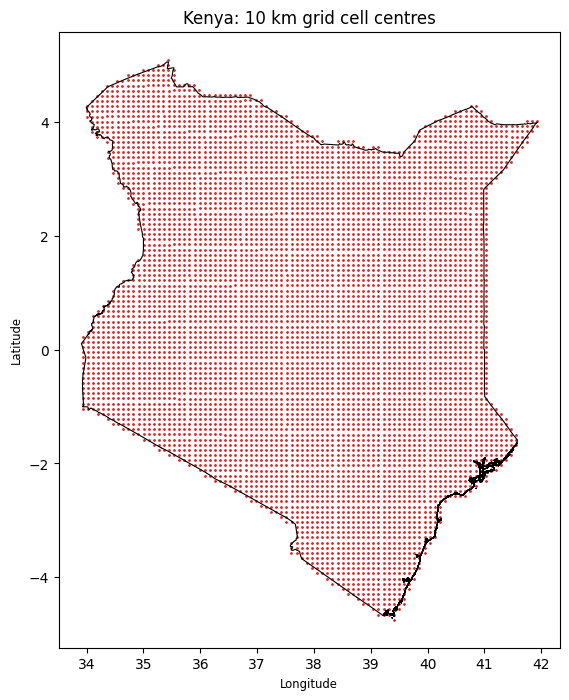

In [13]:
"""
Step 1: Kenya boundary (GADM 4.1) + 10 km grid + cell centres
Run:  python step1_grid.py
Output: kenya_data/kenya_grid_centres.csv and a quick preview plot
"""
import os
import urllib.request
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import shapely
from pyproj import Transformer
from shapely.geometry import box

CELL = 10_000            # 10 km in metres
CRS_M = "EPSG:32737"     # UTM zone 37S (metric CRS that works for Kenya)
OUTDIR = "kenya_data"
os.makedirs(OUTDIR, exist_ok=True)

# --- 1. download the GADM 4.1 shapefile (country outline) ---
zip_path = os.path.join(OUTDIR, "gadm41_KEN_shp.zip")
if not os.path.exists(zip_path):
    print("Downloading GADM shapefile...")
    urllib.request.urlretrieve(
        "https://geodata.ucdavis.edu/gadm/gadm4.1/shp/gadm41_KEN_shp.zip", zip_path
    )
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(OUTDIR)

kenya = gpd.read_file(os.path.join(OUTDIR, "gadm41_KEN_0.shp"))
kenya_m = kenya.to_crs(CRS_M)
kenya_geom = kenya_m.geometry.union_all()

# --- 2. build the 10 km grid over Kenya's bounding box ---
minx, miny, maxx, maxy = kenya_geom.bounds
xs = np.arange(np.floor(minx / CELL) * CELL, maxx + CELL, CELL)
ys = np.arange(np.floor(miny / CELL) * CELL, maxy + CELL, CELL)

cells = gpd.GeoDataFrame(
    {"cx": np.repeat(xs + CELL / 2, len(ys)), "cy": np.tile(ys + CELL / 2, len(xs))},
    geometry=[box(x, y, x + CELL, y + CELL) for x in xs for y in ys],
    crs=CRS_M,
)

# keep every cell that touches Kenya (partial border cells included)
shapely.prepare(kenya_geom)
cells = cells[cells.intersects(kenya_geom)].reset_index(drop=True)
cells["cell_id"] = np.arange(len(cells))

# --- 3. centre of each cell, converted to lon/lat ---
to_ll = Transformer.from_crs(CRS_M, "EPSG:4326", always_xy=True)
cells["lon"], cells["lat"] = to_ll.transform(cells["cx"].values, cells["cy"].values)

cells[["cell_id", "lon", "lat"]].to_csv(
    os.path.join(OUTDIR, "kenya_grid_centres.csv"), index=False
)
print(f"{len(cells)} cells of 10 km saved to {OUTDIR}/kenya_grid_centres.csv")

# --- 4. quick preview ---
fig, ax = plt.subplots(figsize=(7, 8))
kenya.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.scatter(cells["lon"], cells["lat"], s=1, color="tab:red")
ax.set_title("Kenya: 10 km grid cell centres")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.show()

In [14]:
!pip install -q cdsapi netCDF4 xarray


Paste your CDS personal access token: ··········


2026-11-01 17:59:12,002 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-01 17:59:12,355 INFO Request ID is 8df72372-2ad7-4326-8b74-5fa35a317803
INFO:ecmwf.datastores.legacy_client:Request ID is 8df72372-2ad7-4326-8b74-5fa35a317803
2026-11-01 17:59:12,506 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2

15cdc01e91dbcc440f955d5b3587b40d.nc:   0%|          | 0.00/282k [00:00<?, ?B/s]

Downloaded t2m_2026-10-27.nc


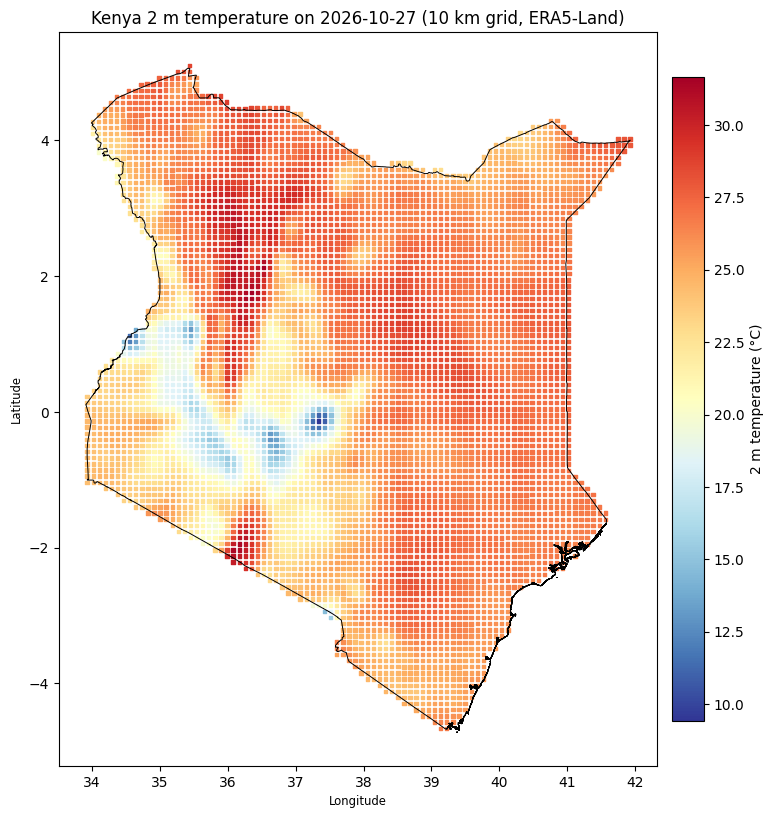

In [15]:
# Steps 2 and 3 for Google Colab.
# Run AFTER step1_grid.py in the same notebook, because these cells reuse
# the `cells` and `kenya` variables it created.
# Each "CELL" block below goes into its own Colab cell.

# ===================== CELL 2: download temperature =====================
import getpass
import cdsapi

DATE = "2026-10-27"          # Updated to a date that is available in the CDS dataset
year, month, day = DATE.split("-")

key = getpass.getpass("Paste your CDS personal access token: ")
client = cdsapi.Client(url="https://cds.climate.copernicus.eu/api", key=key)

nc_path = f"t2m_{DATE}.nc"
client.retrieve(
    "reanalysis-era5-land",
    {
        "variable": ["2m_temperature"],
        "year": year, "month": month, "day": day,
        "time": [f"{h:02d}:00" for h in range(24)],
        "area": [5.7, 33.5, -5.0, 42.0],     # N, W, S, E around Kenya
        "data_format": "netcdf",
        "download_format": "unarchived",
    },
    nc_path,
)
print("Downloaded", nc_path)


# ============== CELL 3: sample at each 10 km centre and plot ==============
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

ds = xr.open_dataset(nc_path)
tdim = "valid_time" if "valid_time" in ds.dims else "time"

t2m = ds["t2m"].mean(tdim) - 273.15                       # daily mean, Kelvin -> degC
t2m = t2m.sortby("latitude").sortby("longitude")

lon = xr.DataArray(cells["lon"].values, dims="p")
lat = xr.DataArray(cells["lat"].values, dims="p")
temp = t2m.interp(longitude=lon, latitude=lat, method="linear").values
nearest = t2m.sel(longitude=lon, latitude=lat, method="nearest").values
cells["temp_C"] = np.where(np.isnan(temp), nearest, temp)  # fill coast/lake gaps

cells[["cell_id", "lon", "lat", "temp_C"]].to_csv(f"kenya_10km_temp_{DATE}.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(cells["lon"], cells["lat"], c=cells["temp_C"], s=6, marker="s", cmap="RdYlBu_r")
kenya.boundary.plot(ax=ax, color="black", linewidth=0.7)
cb = fig.colorbar(sc, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("2 m temperature (°C)")
ax.set_title(f"Kenya 2 m temperature on {DATE} (10 km grid, ERA5-Land)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(f"kenya_temperature_{DATE}.png", dpi=200)
plt.show()